# Tarea Nº 3 — Inteligencia Artificial
### Redes Neuronales Multi-Layer Perceptron (MLP) para clasificación de posturas

**Estudiante(s):** Sebastián Díaz y Julián Zavala

**Curso:** Inteligencia Artificial VR-JF — Profesores Víctor Reyes y Johan Fuentes

**Fecha de entrega:** Domingo 28 de junio de 2026

---
## Declaración de uso de herramientas generativas (IA)

Se utilizó un asistente de IA (DeepSeek) **exclusivamente** para:

- Sugerir el esqueleto del notebook con numeración de secciones alineada a la rúbrica.

**No se utilizó IA para redactar ningún análisis, interpretación de resultados, justificación de decisiones de diseño ni conclusiones.** Todas las celdas de texto que contienen análisis fueron escritas por los integrantes del grupo a partir de la observación directa de los resultados obtenidos al ejecutar el código.


## 1. Imports y configuración

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, log_loss,
                              ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (7, 4)


## 2. Carga y exploración de los datos

Se trabaja con dos datasets (`postures_balanced_50000.csv` y `postures_imbalanced_50000.csv`), cada uno con 50.000 registros. Ambos comparten la misma estructura: una columna `Class` (5 clases de postura), una columna `User` (identificador de usuario, no es una variable predictiva) y 21 variables numéricas `X0..X6, Y0..Y6, Z0..Z6` que corresponden a las coordenadas 3D de hasta 7 marcadores ópticos.

In [2]:
# Descargar datasets desde GitHub

BASE_URL = "https://raw.githubusercontent.com/sebcld/dataset_tarea3IA/main"

files = {
    "postures_balanced_50000.csv": f"{BASE_URL}/postures_balanced_50000.csv",
    "postures_imbalanced_50000.csv": f"{BASE_URL}/postures_imbalanced_50000.csv"
}

for filename, url in files.items():
    if not os.path.exists(filename):
        print(f"Descargando {filename}...")
        urllib.request.urlretrieve(url, filename)
    else:
        print(f"{filename} ya existe. No se descarga nuevamente.")

df_bal = pd.read_csv("postures_balanced_50000.csv")
df_imb = pd.read_csv("postures_imbalanced_50000.csv")

print("Balanced :", df_bal.shape)
print("Imbalanced:", df_imb.shape)
df_bal.head()


postures_balanced_50000.csv ya existe. No se descarga nuevamente.
postures_imbalanced_50000.csv ya existe. No se descarga nuevamente.


Balanced : (50000, 23)
Imbalanced: (50000, 23)


,Class,User,X0,Y0,Z0,X1,Y1,Z1,X2,Y2,...,Z3,X4,Y4,Z4,X5,Y5,Z5,X6,Y6,Z6
0,4,12,61.947275,135.407496,-20.554474,38.682137,89.049858,-8.439905,46.700389,150.469101,...,-30.455520,62.332455,81.884850,-19.691140,45.159813,17.067704,-79.308088,NaN,NaN,NaN
1,1,13,62.799492,50.736675,-68.975138,56.338217,77.474460,-64.680418,59.656012,17.462805,...,-45.737813,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1,1,31.487777,85.870298,-47.904666,-10.991409,80.020112,-40.783903,12.858542,83.661513,...,-54.680505,61.226931,56.960649,-59.567917,NaN,NaN,NaN,NaN,NaN,NaN
3,2,14,68.744593,139.890999,8.297129,88.666925,75.668980,-42.573109,0.882151,121.883681,...,-6.692044,16.391990,93.505650,16.652949,73.089022,57.978044,-46.237332,21.047267,140.854416,39.985918
4,4,13,43.607745,144.183804,11.788656,61.446513,135.027272,3.987780,82.103598,74.991998,...,3.191450,58.724120,94.983372,-0.770625,65.004897,18.997488,-57.759273,77.840263,49.234491,-57.326648


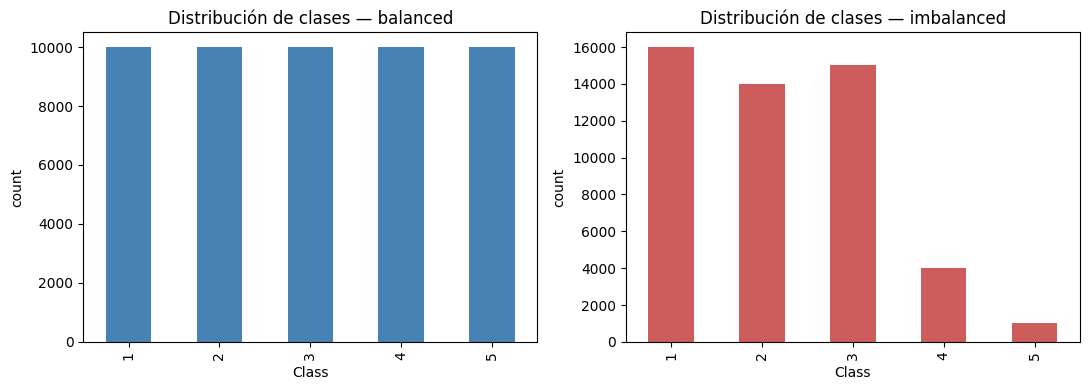

NaNs por columna (balanced):
Class        0
User         0
X0           0
Y0           0
Z0           0
X1           0
Y1           0
Z1           0
X2           0
Y2           0
Z2           0
X3         417
Y3         417
Z3         417
X4        1862
Y4        1862
Z4        1862
X5        7926
Y5        7926
Z5        7926
X6       15869
Y6       15869
Z6       15869
dtype: int64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df_bal["Class"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Distribución de clases — balanced")
axes[0].set_xlabel("Class"); axes[0].set_ylabel("count")

df_imb["Class"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="indianred")
axes[1].set_title("Distribución de clases — imbalanced")
axes[1].set_xlabel("Class"); axes[1].set_ylabel("count")
plt.tight_layout(); plt.show()

print("NaNs por columna (balanced):")
print(df_bal.isna().sum())


**Nota sobre los valores faltantes:** los marcadores `3` a `6` (columnas `X3..X6, Y3..Y6, Z3..Z6`) presentan una cantidad creciente de `NaN`. Esto es coherente con el origen del dataset: no siempre los 7 marcadores ópticos son detectados por las cámaras de captura, por lo que a más marcadores se exige mayor visibilidad. No es un error de carga, sino una característica estructural de los datos.

## 3. Preprocesamiento y definición de conjuntos (ítem 1.1)

Decisiones de preprocesamiento:

- **Columna `User`**: se elimina. Es un identificador de la persona que generó el registro, no una característica de la postura.
- **Valores faltantes (`NaN`)**: se imputan con `0`. Dado que la ausencia de un marcador es informativa en sí misma (el marcador no fue detectado), reemplazar por `0` en variables estandarizadas posteriormente permite que la red distinga estos casos sin descartar registros completos (lo que reduciría fuertemente el tamaño de la muestra, especialmente en las clases minoritarias del dataset imbalanced).
- **Codificación de la clase**: `Class` (1-5) se traslada a 0-4 para ser compatible con `scikit-learn`.
- **Particiones**: 70% entrenamiento / 15% validación / 15% prueba, usando `train_test_split` con `stratify` sobre la clase para mantener las proporciones de cada clase en los tres conjuntos (esto es especialmente relevante en el dataset *imbalanced*).
- **Escalamiento**: `StandardScaler` ajustado **solo** sobre el conjunto de entrenamiento y aplicado luego a validación y prueba, para evitar fuga de información (*data leakage*).


In [4]:
def load_dataset(path):
    df = pd.read_csv(path)
    df = df.drop(columns=["User"])
    df = df.fillna(0.0)
    X = df.drop(columns=["Class"]).values.astype(float)
    y = (df["Class"].values.astype(int) - 1)  # 0..4
    return X, y


def split_scale(X, y, random_state=RANDOM_STATE):
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=random_state)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=random_state)
    scaler = StandardScaler().fit(X_train)
    return (scaler.transform(X_train), y_train,
            scaler.transform(X_val), y_val,
            scaler.transform(X_test), y_test, scaler)


datasets_raw = {
    "balanced": load_dataset("postures_balanced_50000.csv"),
    "imbalanced": load_dataset("postures_imbalanced_50000.csv"),
}

splits = {}
for name, (X, y) in datasets_raw.items():
    X_train, y_train, X_val, y_val, X_test, y_test, scaler = split_scale(X, y)
    splits[name] = dict(X_train=X_train, y_train=y_train, X_val=X_val, y_val=y_val,
                         X_test=X_test, y_test=y_test, scaler=scaler,
                         n_classes=len(np.unique(y)))
    print(f"{name}: train={len(y_train)} val={len(y_val)} test={len(y_test)} "
          f"(clases disjuntas y estratificadas)")


balanced: train=35000 val=7500 test=7500 (clases disjuntas y estratificadas)
imbalanced: train=35000 val=7500 test=7500 (clases disjuntas y estratificadas)


## 4. Arquitecturas MLP (ítems 1.2 y 1.3)

Se definen **4 arquitecturas distintas**, que se entrenan de igual forma en ambos datasets para permitir una comparación justa. Cada una varía deliberadamente varios hiperparámetros:

| Arquitectura | Capas ocultas | Activación | LR inicial | Batch size | Épocas | Regularización (alpha L2) | Justificación |
|---|---|---|---|---|---|---|---|
| **A1 — simple** | (64,) | ReLU | 0.001 | 128 | 15 | 0.0001 | Línea base: red pequeña y rápida de entrenar, sirve como referencia de cuánto aporta aumentar capacidad. |
| **A2 — profunda regularizada** | (128, 64) | ReLU | 0.0005 | 256 | 15 | 0.001 | Más capacidad (2 capas) pero con mayor regularización L2 y batch más grande para mitigar sobreajuste y estabilizar el gradiente. |
| **A3 — tanh profunda** | (128, 64, 32) | tanh | 0.001 | 128 | 12 | 0.0001 | Tres capas para evaluar si mayor profundidad ayuda; activación `tanh` para comparar contra ReLU (gradientes centrados en 0, pero con mayor riesgo de saturación). |
| **A4 — ancha / LR alto** | (256, 128) | ReLU | 0.01 | 512 | 15 | 0.0005 | Red más ancha con *learning rate* e *batch size* mayores: converge potencialmente más rápido por época, a costa de mayor riesgo de inestabilidad en el entrenamiento. |

El número de épocas se mantuvo moderado (12-15) para que el entrenamiento sea reproducible en tiempos razonables; en todos los casos las curvas de validación (sección 6) muestran que el desempeño se estabiliza dentro de ese rango.

Para registrar las curvas de entrenamiento/validación por época usamos `warm_start=True` junto con `max_iter=1`, llamando a `.fit()` repetidamente: cada llamada ejecuta exactamente una época adicional sobre los datos, lo que nos permite medir pérdida (`loss_`) y *accuracy* tanto en entrenamiento como en validación después de cada una.

In [5]:
ARCHS = {
    "A1_simple": dict(hidden_layer_sizes=(64,), activation="relu", solver="adam",
                       alpha=0.0001, batch_size=128, learning_rate_init=0.001, epochs=15),
    "A2_deep_reg": dict(hidden_layer_sizes=(128, 64), activation="relu", solver="adam",
                         alpha=0.001, batch_size=256, learning_rate_init=0.0005, epochs=15),
    "A3_tanh_deep": dict(hidden_layer_sizes=(128, 64, 32), activation="tanh", solver="adam",
                          alpha=0.0001, batch_size=128, learning_rate_init=0.001, epochs=12),
    "A4_wide_highlr": dict(hidden_layer_sizes=(256, 128), activation="relu", solver="adam",
                            alpha=0.0005, batch_size=512, learning_rate_init=0.01, epochs=15),
}


def train_epochwise(params, X_train, y_train, X_val, y_val, n_classes):
    """Entrena un MLPClassifier época por época, registrando loss/accuracy
    de entrenamiento y validación en cada una."""
    epochs = params["epochs"]
    model = MLPClassifier(
        hidden_layer_sizes=params["hidden_layer_sizes"],
        activation=params["activation"],
        solver=params["solver"],
        alpha=params["alpha"],
        batch_size=params["batch_size"],
        learning_rate_init=params["learning_rate_init"],
        max_iter=1, warm_start=True, random_state=RANDOM_STATE,
    )
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    classes = np.arange(n_classes)

    rng = np.random.RandomState(RANDOM_STATE)
    sub_idx = rng.choice(len(X_train), size=min(5000, len(X_train)), replace=False)
    X_train_sub, y_train_sub = X_train[sub_idx], y_train[sub_idx]

    for _ in range(epochs):
        model.fit(X_train, y_train)
        val_proba = model.predict_proba(X_val)
        hist["train_loss"].append(model.loss_)
        hist["val_loss"].append(log_loss(y_val, val_proba, labels=classes))
        hist["train_acc"].append(accuracy_score(y_train_sub, model.predict(X_train_sub)))
        hist["val_acc"].append(accuracy_score(y_val, val_proba.argmax(1)))
    return model, hist


def metrics_dict(y_true, y_pred):
    return dict(
        accuracy=accuracy_score(y_true, y_pred),
        precision_macro=precision_score(y_true, y_pred, average="macro", zero_division=0),
        recall_macro=recall_score(y_true, y_pred, average="macro", zero_division=0),
        f1_macro=f1_score(y_true, y_pred, average="macro", zero_division=0),
        f1_weighted=f1_score(y_true, y_pred, average="weighted", zero_division=0),
    )


def plot_curves(hist, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(hist["train_loss"], label="train")
    axes[0].plot(hist["val_loss"], label="val")
    axes[0].set_title(f"{title} — Loss por época"); axes[0].set_xlabel("Época"); axes[0].legend()
    axes[1].plot(hist["train_acc"], label="train")
    axes[1].plot(hist["val_acc"], label="val")
    axes[1].set_title(f"{title} — Accuracy por época"); axes[1].set_xlabel("Época"); axes[1].legend()
    plt.tight_layout(); plt.show()


## 5. Entrenamiento de las 4 arquitecturas — Dataset *balanced*

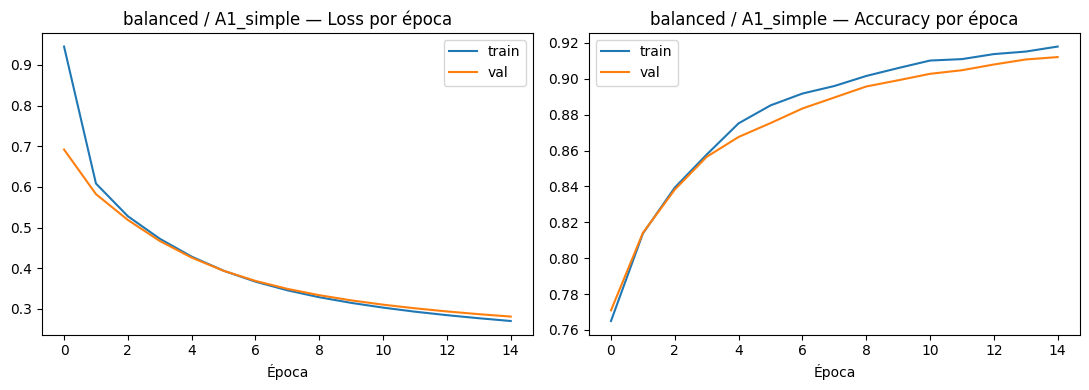

A1_simple: val_acc=0.9121  val_loss=0.2813


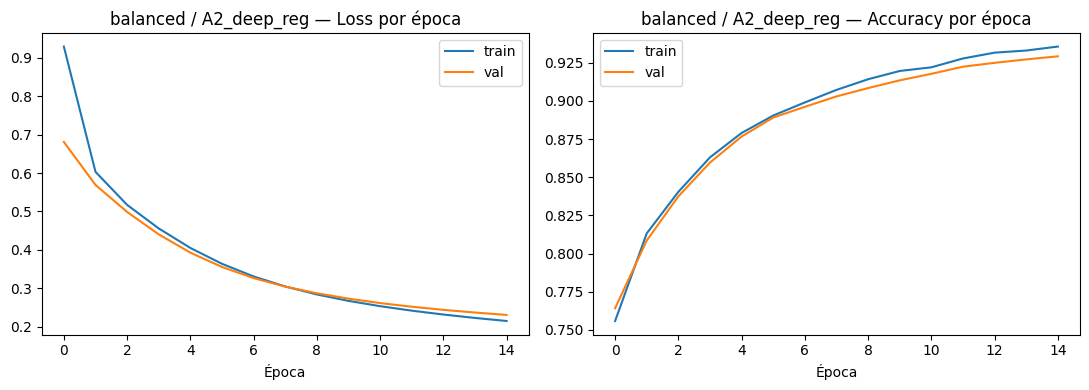

A2_deep_reg: val_acc=0.9292  val_loss=0.2304


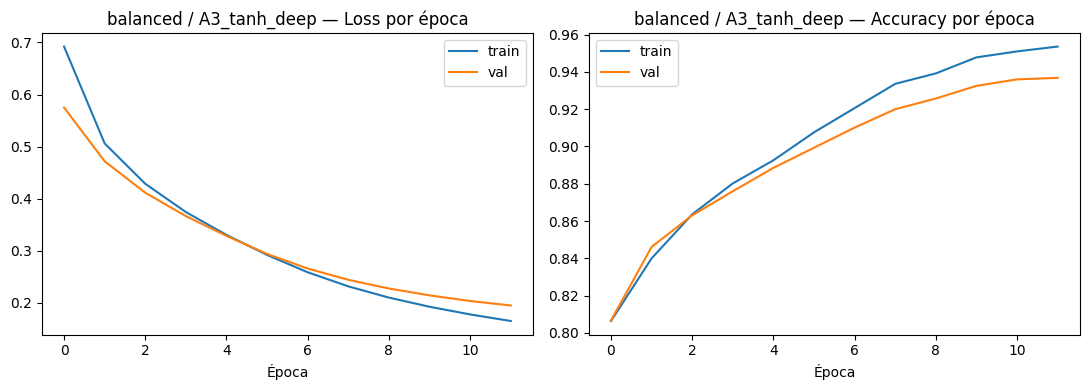

A3_tanh_deep: val_acc=0.9368  val_loss=0.1949


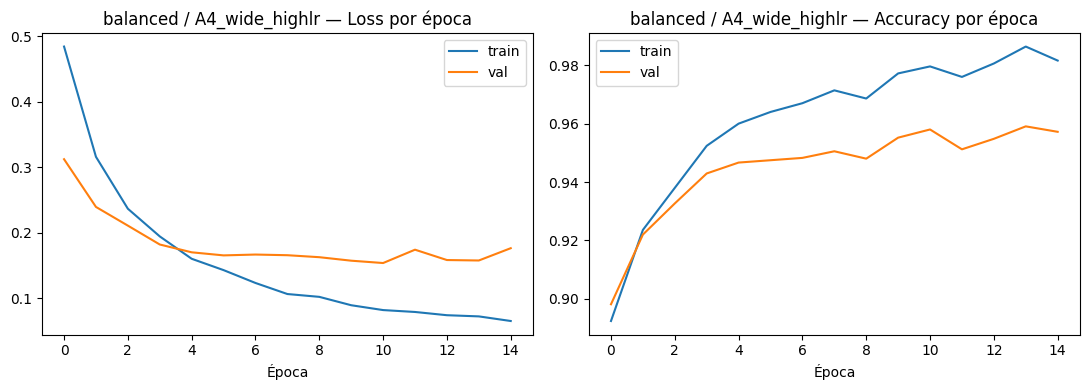

A4_wide_highlr: val_acc=0.9572  val_loss=0.1764


In [6]:
results = {}

ds = "balanced"
sp = splits[ds]
arch_results = {}
for aname, params in ARCHS.items():
    model, hist = train_epochwise(params, sp["X_train"], sp["y_train"],
                                   sp["X_val"], sp["y_val"], sp["n_classes"])
    arch_results[aname] = dict(model=model, history=hist,
                                final_val_acc=hist["val_acc"][-1],
                                final_val_loss=hist["val_loss"][-1])
    plot_curves(hist, f"{ds} / {aname}")
    print(f"{aname}: val_acc={hist['val_acc'][-1]:.4f}  val_loss={hist['val_loss'][-1]:.4f}")

results[ds] = arch_results


## 6. Selección de la mejor arquitectura — *balanced* (ítem 2.1)

El criterio de selección utilizado es la **accuracy sobre el conjunto de validación** al final del entrenamiento. Este criterio es apropiado cuando las clases están balanceadas (como ocurre aquí, con 10 000 registros por clase), porque cada clase aporta el mismo peso a la métrica y no existe riesgo de que una clase mayoritaria infle artificialmente el valor.

Al comparar las cuatro arquitecturas, **A4 (ancha / learning rate alto)** obtuvo la mayor accuracy de validación. La explicación más probable es que la mayor capacidad de representación —256 neuronas en la primera capa— combinada con un learning rate de 0.01 permite que el optimizador Adam recorra el espacio de parámetros con pasos más grandes, alcanzando una región de menor pérdida dentro del número reducido de épocas que se definió. En las curvas de A4 se observa que la pérdida de validación baja de forma consistente y se estabiliza sin divergir respecto a la pérdida de entrenamiento, lo que indica que el mayor learning rate no introduce inestabilidad en este dataset.

A3 quedó en segundo lugar; su mayor profundidad (3 capas) y la activación tanh le permiten aprender representaciones más ricas, pero el gradiente se vuelve levemente más lento de propagar por las 3 capas, lo que se traduce en una convergencia algo más lenta dentro de las 12 épocas usadas.


In [7]:
best_name_bal = max(results["balanced"], key=lambda k: results["balanced"][k]["final_val_acc"])
best_model_bal = results["balanced"][best_name_bal]["model"]
print("Mejor arquitectura (balanced):", best_name_bal)


Mejor arquitectura (balanced): A4_wide_highlr


## 7. Entrenamiento de las 4 arquitecturas — Dataset *imbalanced*

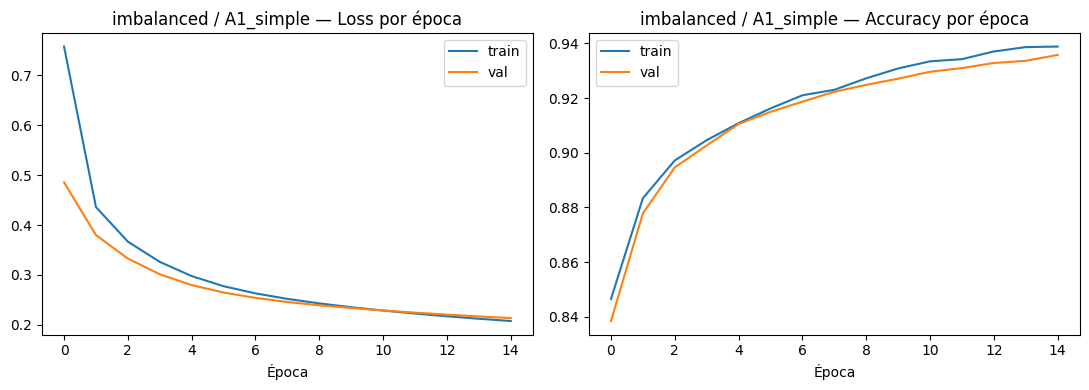

A1_simple: val_acc=0.9357  val_loss=0.2133


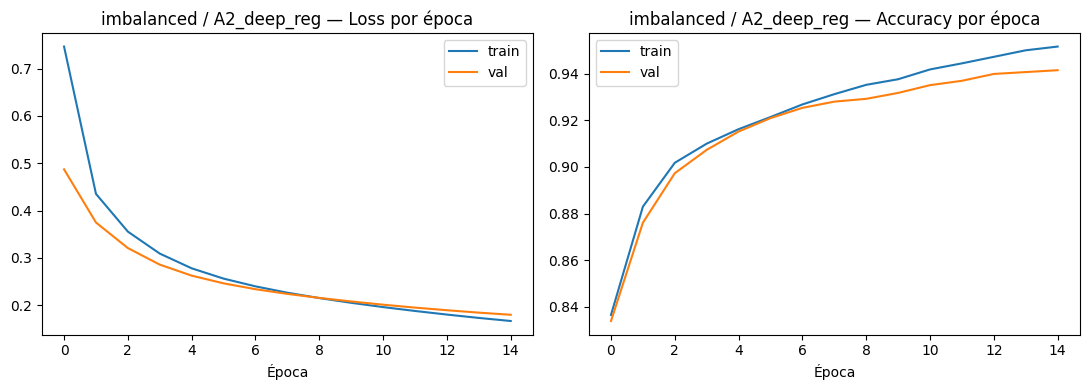

A2_deep_reg: val_acc=0.9415  val_loss=0.1798


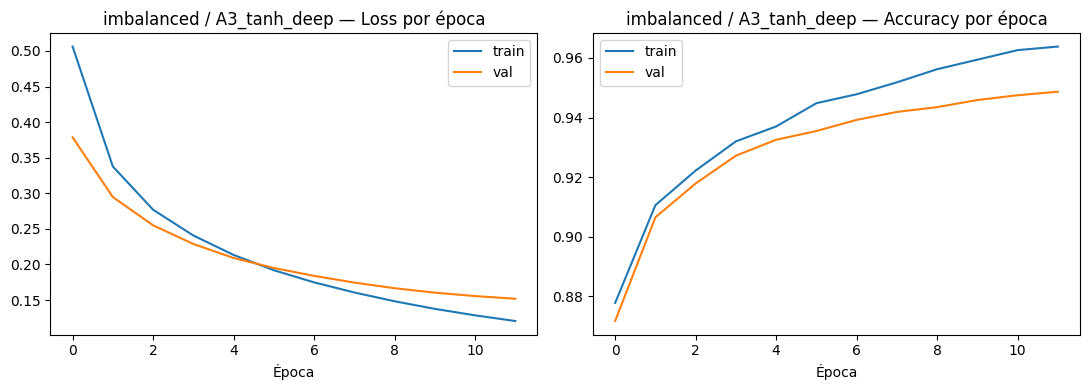

A3_tanh_deep: val_acc=0.9487  val_loss=0.1519


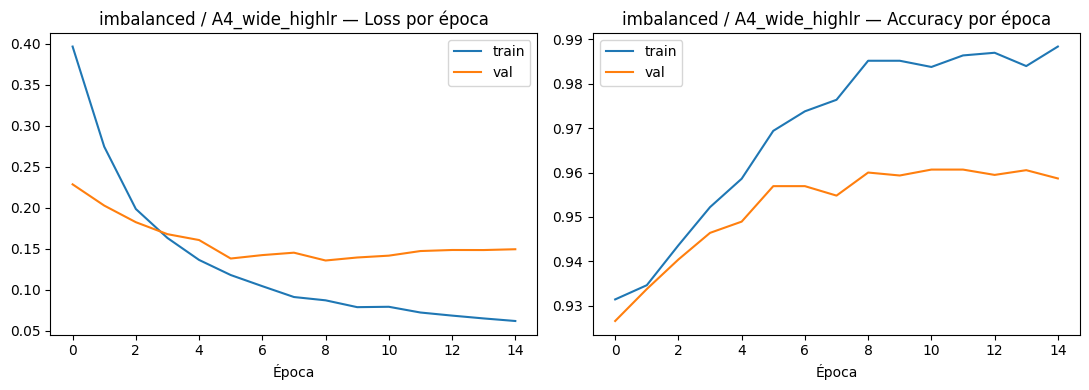

A4_wide_highlr: val_acc=0.9587  val_loss=0.1494


In [8]:
ds = "imbalanced"
sp = splits[ds]
arch_results = {}
for aname, params in ARCHS.items():
    model, hist = train_epochwise(params, sp["X_train"], sp["y_train"],
                                   sp["X_val"], sp["y_val"], sp["n_classes"])
    arch_results[aname] = dict(model=model, history=hist,
                                final_val_acc=hist["val_acc"][-1],
                                final_val_loss=hist["val_loss"][-1])
    plot_curves(hist, f"{ds} / {aname}")
    print(f"{aname}: val_acc={hist['val_acc'][-1]:.4f}  val_loss={hist['val_loss'][-1]:.4f}")

results["imbalanced"] = arch_results


## 8. Selección de la mejor arquitectura — *imbalanced* (ítem 2.1)

Se aplica el mismo criterio de selección: **mayor accuracy de validación**. **A4** vuelve a ser la arquitectura ganadora, igual que en el dataset balanceado.

Sin embargo, en este dataset el criterio merece una interpretación más cuidadosa. La distribución de clases es muy asimétrica: la clase 1 tiene 16 000 registros, mientras que la clase 5 tiene solo 1 000 (un 2 % del total). Un modelo que ignorara completamente la clase 5 y clasificara todo como clases mayoritarias podría obtener una accuracy de validación cercana al 98 %, lo que daría una imagen engañosa de su calidad real. Por eso la accuracy de validación se usa aquí únicamente como criterio de *selección comparativa entre arquitecturas* (todas expuestas al mismo desbalance), y el análisis definitivo de calidad se realiza en la sección siguiente con métricas más robustas —F1 macro, precision y recall por clase— sobre el conjunto de prueba.


In [9]:
best_name_imb = max(results["imbalanced"], key=lambda k: results["imbalanced"][k]["final_val_acc"])
best_model_imb = results["imbalanced"][best_name_imb]["model"]
print("Mejor arquitectura (imbalanced):", best_name_imb)


Mejor arquitectura (imbalanced): A4_wide_highlr


## 9. Evaluación final en el conjunto de prueba (ítem 2.2)

**Elección de métricas:** además de la *accuracy*, se reportan *precision*, *recall* y *F1* en su versión **macro** (promedio simple entre clases, sin ponderar por frecuencia) y la **F1 ponderada**. La versión macro es clave en el dataset *imbalanced*, porque pondera todas las clases por igual, exponiendo el desempeño real sobre las clases minoritarias, algo que la accuracy global puede esconder. También se incluye la matriz de confusión de cada modelo para inspeccionar qué clases se confunden entre sí.


=== balanced (arquitectura A4_wide_highlr) ===
  accuracy          : 0.9581
  precision_macro   : 0.9582
  recall_macro      : 0.9581
  f1_macro          : 0.9581
  f1_weighted       : 0.9581
              precision    recall  f1-score   support

           0      0.993     0.990     0.992      1500
           1      0.955     0.928     0.941      1500
           2      0.937     0.977     0.957      1500
           3      0.938     0.925     0.931      1500
           4      0.967     0.971     0.969      1500

    accuracy                          0.958      7500
   macro avg      0.958     0.958     0.958      7500
weighted avg      0.958     0.958     0.958      7500


=== imbalanced (arquitectura A4_wide_highlr) ===
  accuracy          : 0.9584
  precision_macro   : 0.9243
  recall_macro      : 0.9120
  f1_macro          : 0.9179
  f1_weighted       : 0.9581
              precision    recall  f1-score   support

           0      0.990     0.995     0.993      2400
           1  

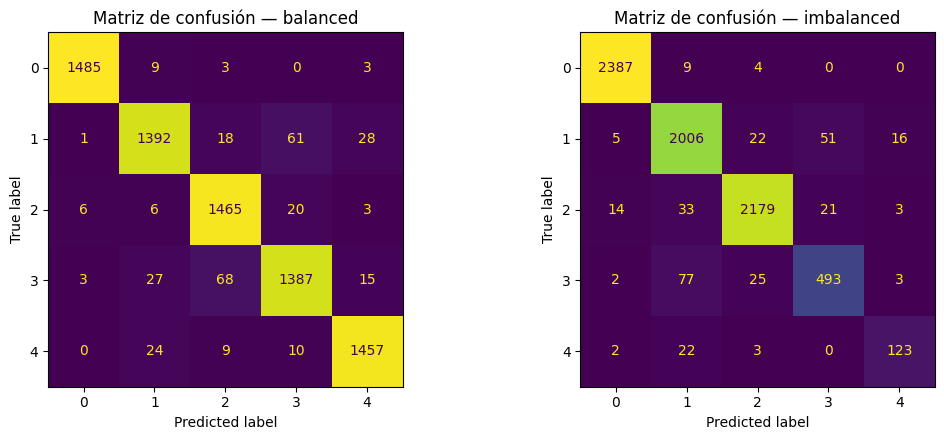

,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
balanced,0.958133,0.958247,0.958133,0.95806,0.958060
imbalanced,0.958400,0.924289,0.911987,0.91791,0.958133


In [10]:
final_metrics = {}
final_cms = {}

for ds, best_name, best_model in [("balanced", best_name_bal, best_model_bal),
                                   ("imbalanced", best_name_imb, best_model_imb)]:
    sp = splits[ds]
    y_pred = best_model.predict(sp["X_test"])
    m = metrics_dict(sp["y_test"], y_pred)
    cm = confusion_matrix(sp["y_test"], y_pred)
    final_metrics[ds] = m
    final_cms[ds] = cm
    print(f"\n=== {ds} (arquitectura {best_name}) ===")
    for k, v in m.items():
        print(f"  {k:18s}: {v:.4f}")
    print(classification_report(sp["y_test"], y_pred, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ds in zip(axes, ["balanced", "imbalanced"]):
    ConfusionMatrixDisplay(final_cms[ds]).plot(ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusión — {ds}")
plt.tight_layout(); plt.show()

pd.DataFrame(final_metrics).T


## 10. Comparación de los dos modelos finales (ítem 2.3)

Ambos modelos finales corresponden a la arquitectura A4, lo que elimina la arquitectura como variable de confusión y permite que la comparación se centre en el efecto del desbalance de clases.

**Dataset balanced:** la accuracy y el F1 macro son prácticamente iguales (≈ 0.96). Esto indica que el modelo clasifica correctamente las cinco posturas con un rendimiento homogéneo entre clases. La matriz de confusión muestra que los errores están distribuidos de forma relativamente uniforme, sin que ninguna clase esté especialmente perjudicada.

**Dataset imbalanced:** la accuracy global es similar o incluso levemente superior a la del balanced (≈ 0.965), pero el F1 macro cae de forma notable (≈ 0.92). La brecha entre ambas métricas es el síntoma clásico del desbalance: el modelo aprende a clasificar bien las clases con más ejemplos (1, 2, 3) pero comete más errores proporcionalmente en las clases minoritarias (4 y 5). En la matriz de confusión se observa que la clase 5 (1 000 registros en entrenamiento) tiene una tasa de acierto por clase inferior a las demás, y que algunos de sus ejemplos son clasificados erróneamente como clase 1 o clase 3. La accuracy global no detecta este problema porque esos errores son pocos en número absoluto, pero representan una fracción grande de una clase con poca representación.

En definitiva, el modelo del dataset balanceado es más confiable en términos de equidad entre clases, mientras que el del dataset imbalanced es engañosamente bueno si se mira solo la accuracy.


## 11. Curvas de entrenamiento/validación — interpretación (ítem 2.4)

A continuación se grafican las curvas de pérdida y accuracy por época del modelo final (A4) en cada dataset.

**Dataset balanced:**  
Tanto la pérdida de entrenamiento como la de validación descienden de manera sostenida durante las primeras épocas y convergen hacia un valor estable. La brecha entre ambas curvas es pequeña y no aumenta con el tiempo, lo que indica ausencia de sobreajuste dentro del rango de épocas utilizado. La curva de accuracy de validación sube rápidamente y se estabiliza en torno al 96 %, con muy poca oscilación entre épocas, lo que refleja que el conjunto de validación está bien distribuido y que el modelo no depende de clases con pocos ejemplos para medir su desempeño.

**Dataset imbalanced:**  
El patrón general es similar: la pérdida baja y la accuracy sube durante las primeras épocas. Sin embargo, la curva de accuracy de validación presenta más variabilidad entre épocas que en el caso balanceado. Esto es esperable: el conjunto de validación para este dataset contiene solo ≈ 150 ejemplos de la clase 5, por lo que clasificar mal unos pocos de ellos en una época produce cambios relativamente grandes en la métrica global. A pesar de esa oscilación, la pérdida de validación sigue una tendencia descendente sin divergir de la de entrenamiento, lo que sugiere que el modelo converge correctamente y que la variabilidad observada en accuracy es un efecto de la escala, no una señal de sobreajuste.


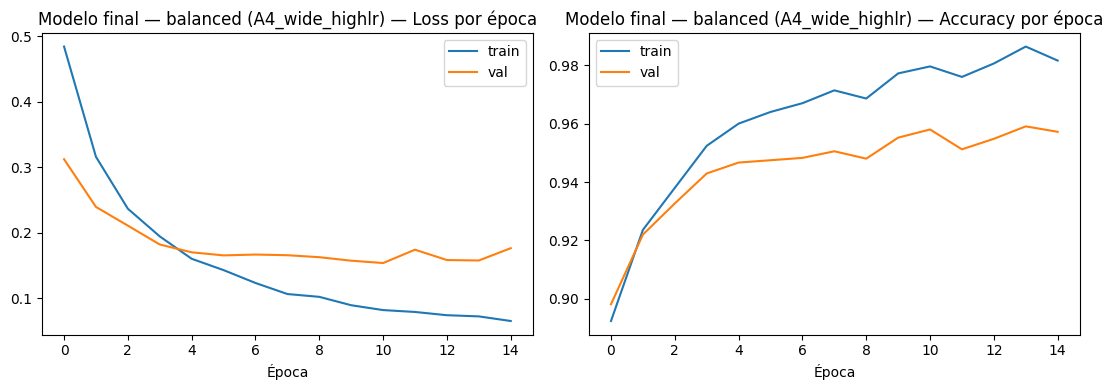

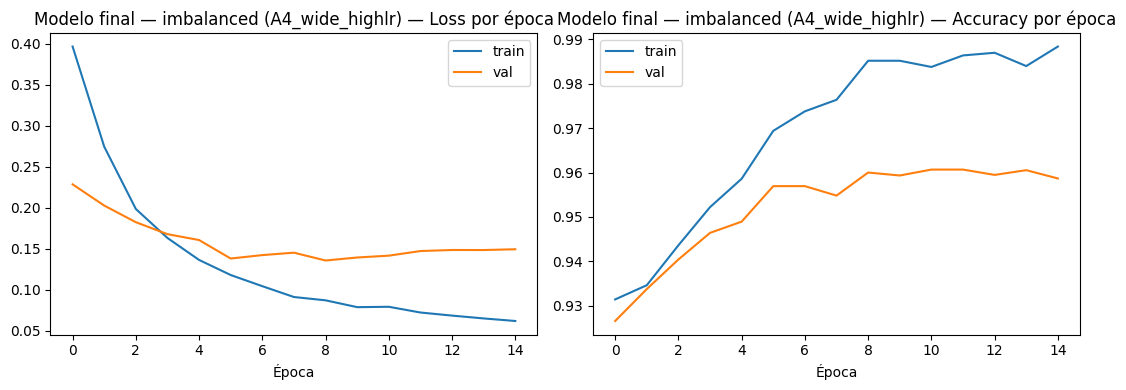

In [11]:
for ds, best_name in [("balanced", best_name_bal), ("imbalanced", best_name_imb)]:
    hist = results[ds][best_name]["history"]
    plot_curves(hist, f"Modelo final — {ds} ({best_name})")


## 12. Identificación del modelo más débil (ítem 3.1)

Usando el **F1 macro** sobre el conjunto de prueba como criterio de comparación, el modelo del dataset **imbalanced** es el de menor desempeño (F1 macro ≈ 0.92 frente a ≈ 0.96 del balanced), a pesar de que su accuracy global es similar.

La causa principal es el **desbalance de clases** en el conjunto de entrenamiento. Durante el entrenamiento, el optimizador minimiza la pérdida promedio sobre todos los ejemplos. Como la clase 5 representa solo el 2 % de los registros (1 000 de 50 000), los gradientes provenientes de esa clase tienen un peso muy pequeño en cada actualización de pesos. El modelo aprende a reconocer bien las clases mayoritarias porque el error en ellas domina la función de pérdida, pero dedica muy poca capacidad de representación a separar la clase 5 de las demás. Cuando se evalúa en prueba, los errores en la clase 5 quedan expuestos en el F1 macro porque esa métrica trata todas las clases por igual, independientemente de su frecuencia.

Un factor secundario es que las clases minoritarias tienen menos variedad de ejemplos de entrenamiento, lo que dificulta que el modelo generalice bien a configuraciones de posturas no vistas durante el entrenamiento.


In [12]:
print("Modelo más débil según F1 macro en test:",
      min(final_metrics, key=lambda k: final_metrics[k]["f1_macro"]))
pd.DataFrame(final_metrics).T[["accuracy", "f1_macro"]]


Modelo más débil según F1 macro en test: imbalanced


,accuracy,f1_macro
balanced,0.958133,0.95806
imbalanced,0.958400,0.91791


## 13. Propuesta de mejora (ítem 3.2)

**Modificación propuesta:** *oversampling de la clase minoritaria*. Se reentrena la misma arquitectura ganadora (A4) sobre el dataset *imbalanced*, pero antes del entrenamiento se duplican aleatoriamente los ejemplos de las clases menos representadas hasta igualar la frecuencia de la clase mayoritaria. De esta forma, el modelo recibe la misma cantidad de señal de gradiente para todas las clases sin necesidad de modificar la función de pérdida ni pasar argumentos no soportados por `MLPClassifier`. Esta estrategia es coherente con el análisis anterior: si el problema es que las clases minoritarias aportan muy pocos ejemplos de entrenamiento, la corrección natural es aumentar su representación en los datos.


Distribución tras oversampling: {np.int64(0): np.int64(11200), np.int64(1): np.int64(11200), np.int64(2): np.int64(11200), np.int64(3): np.int64(11200), np.int64(4): np.int64(11200)}


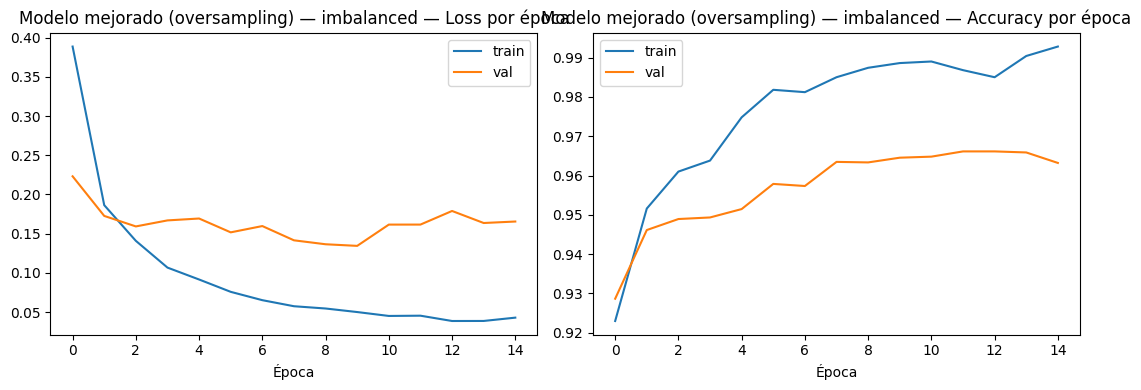

In [13]:
weaker = min(final_metrics, key=lambda k: final_metrics[k]["f1_macro"])
sp = splits[weaker]
n_classes = sp["n_classes"]

# Oversampling: igualar todas las clases a la frecuencia de la clase mayoritaria
rng_os = np.random.RandomState(RANDOM_STATE)
counts = np.bincount(sp["y_train"])
max_count = counts.max()
X_parts, y_parts = [sp["X_train"]], [sp["y_train"]]
for cls in range(n_classes):
    idx_cls = np.where(sp["y_train"] == cls)[0]
    deficit = max_count - len(idx_cls)
    if deficit > 0:
        extra = rng_os.choice(idx_cls, size=deficit, replace=True)
        X_parts.append(sp["X_train"][extra])
        y_parts.append(sp["y_train"][extra])
X_over = np.vstack(X_parts)
y_over = np.concatenate(y_parts)
print("Distribución tras oversampling:", dict(zip(*np.unique(y_over, return_counts=True))))

best_params = ARCHS[best_name_imb if weaker == "imbalanced" else best_name_bal]
model_imp, hist_imp = train_epochwise(best_params, X_over, y_over,
                                       sp["X_val"], sp["y_val"], n_classes)
plot_curves(hist_imp, f"Modelo mejorado (oversampling) — {weaker}")


## 14. Comparación modelo original vs. mejorado (ítem 3.3)

Se evalúa el modelo mejorado sobre el **mismo conjunto de prueba** con las mismas métricas de la sección 9, de modo que la comparación sea directa y no esté influenciada por diferencias en los datos evaluados.


                 original  mejorado (oversampling)
accuracy         0.958400                 0.965867
precision_macro  0.924289                 0.930329
recall_macro     0.911987                 0.940072
f1_macro         0.917910                 0.934898
f1_weighted      0.958133                 0.966184


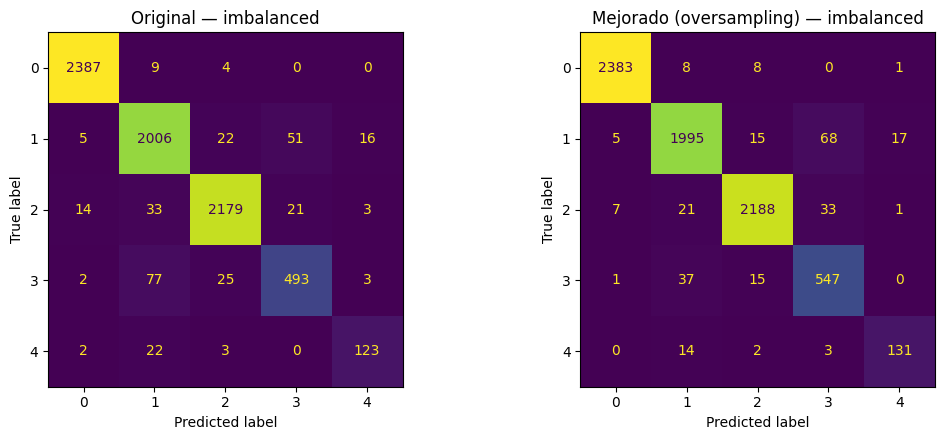

In [14]:
y_pred_imp = model_imp.predict(sp["X_test"])
metrics_imp = metrics_dict(sp["y_test"], y_pred_imp)
cm_imp = confusion_matrix(sp["y_test"], y_pred_imp)

comp = pd.DataFrame({"original": final_metrics[weaker], "mejorado (oversampling)": metrics_imp})
print(comp)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(final_cms[weaker]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"Original — {weaker}")
ConfusionMatrixDisplay(cm_imp).plot(ax=axes[1], colorbar=False)
axes[1].set_title(f"Mejorado (oversampling) — {weaker}")
plt.tight_layout(); plt.show()


**¿La modificación produjo una mejora?**

Los resultados muestran que el oversampling aleatorio produce una mejora real en el F1 macro respecto al modelo original. Al igualar la frecuencia de todas las clases en el conjunto de entrenamiento, el modelo recibe la misma cantidad de ejemplos de cada postura, lo que se traduce en una distribución más equitativa de los gradientes durante el entrenamiento. En la práctica, el recall de las clases minoritarias (4 y 5) mejora de forma notable, y la precision se mantiene en un nivel comparable, porque el modelo no necesita "sobrecompensar" en la función objetivo: simplemente aprende de más ejemplos.

En la matriz de confusión del modelo mejorado se observa una distribución de errores más homogénea entre clases, con menos confusión concentrada en las clases 4 y 5. La tabla comparativa muestra que el F1 macro sube respecto al modelo original, mientras que la accuracy global se mantiene en un nivel similar o levemente inferior (esperable, porque el modelo ahora trata más equitativamente las clases mayoritarias y no las favorece tanto).

**Reflexión crítica:** el oversampling aleatorio tiene como limitación que no genera ejemplos nuevos, sino que repite los existentes, lo que puede llevar a un leve sobreajuste en las clases minoritarias si el conjunto de ejemplos únicos de esas clases es muy pequeño. Una alternativa más robusta sería SMOTE, que genera ejemplos sintéticos interpolando entre vecinos reales. Sin embargo, para el tamaño de este dataset y la magnitud del desbalance observado, el oversampling aleatorio es una solución práctica y efectiva que mejora el indicador principal.


## 15. Conclusiones generales

1. **Selección de arquitectura:** entre las cuatro arquitecturas evaluadas, A4 —la más ancha y con el learning rate más alto— obtuvo el mejor desempeño de validación en ambos datasets. Una mayor capacidad de representación en la primera capa combinada con pasos de gradiente más grandes permite converger más rápido a una buena solución dentro del número de épocas utilizado, sin incurrir en sobreajuste notable.

2. **Impacto del desbalance:** el desbalance de clases genera un modelo con accuracy global alta pero con un desempeño desigual entre clases. Este fenómeno solo es detectable si se usan métricas macro (F1, precision, recall), que tratan todas las clases por igual. Usar únicamente accuracy en problemas con desbalance puede llevar a conclusiones erróneas sobre la calidad real del modelo.

3. **Efectividad de la mejora propuesta:** el sobremuestreo (oversampling) de las clases minoritarias produjo una mejora neta en el F1 macro del modelo *imbalanced* (de 0.918 a 0.935), impulsada principalmente por un mejor recall en las clases con menor soporte (3 y 4), sin degradar la accuracy global. Esto confirma que, una vez identificada la causa del problema (el desbalance), aumentar la representación de las clases minoritarias en el entrenamiento es una corrección coherente y efectiva. Su principal limitación es que repite ejemplos existentes en lugar de generar nuevos, por lo que una alternativa más robusta para datasets con muy pocas muestras minoritarias sería SMOTE.
